In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
import copy
import pickle

from collections import defaultdict

import torch
import torch.nn as nn
import numpy as np
from tqdm import tqdm

import matplotlib.pyplot as plt

import schnetpack as spk
from schnetpack.datasets import MD17

from imlff.common.util import proj_path
from imlff.model.solvers import fixed_point_iteration, anderson
from imlff.model.util import init_iterating_schnet, adapt_apply_state_dict
from imlff.data.util import load_md17_data

from imlff.loading import load_model, load_model_from_wandb

from schnetpack.representation import SchNet, PaiNN

from torchmetrics.functional.regression.mae import mean_absolute_error
from tqdm.notebook import tqdm

from imlff.visualization.trajectory import minimize_rmsd_traj_auto_mask, arrays_to_atoms_list, atoms_list_to_arrays
import nglview as nv
from nglview import show_ase, show_asetraj
from ase import Atoms
import seaborn as sns

device = 'cuda' if torch.cuda.is_available() else 'cpu'
# device='mps'

## dataset analysis

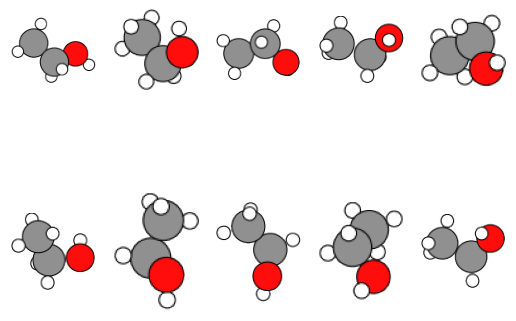

In [17]:
from pathlib import Path
from ase import Atoms
from ase.visualize import view
from ase.io import write

Path("/tmp/pictures").mkdir(exist_ok=True)

for i in range(10):
    # create atoms object from dataset
    structure = data[i]
    atoms = Atoms(
        numbers=structure[spk.properties.Z].cpu(), positions=structure[spk.properties.R].cpu()
    )

    # view(atoms, viewer="x3d")
    write(f"/tmp/pictures/structure_{i}.png", atoms)
    
# now plot pngs with matplotlib
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(plt.imread(f"/tmp/pictures/structure_{i}.png"))
    plt.axis("off")

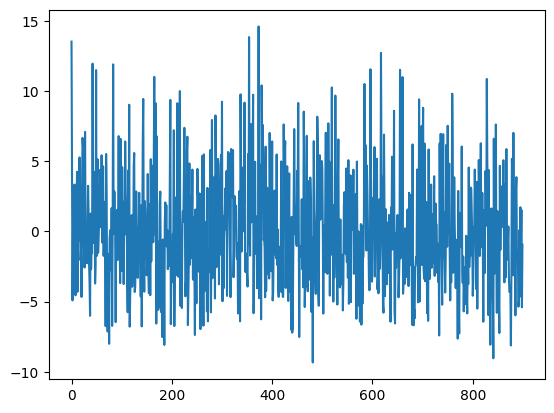

In [13]:
energies = []

for i in range(900):
    structure = data[i]
    energies.append(structure[MD17.energy].cpu())
    
plt.plot(energies)

# Are fixed points continous wrt. input?

In [4]:
molecule_name, tag_deq = 'azobenzene', 'qcml-group/v7/model-a76tw6ap:v6179' # deq best performing so far
molecule_name, tag_deq = 'malonaldehyde', 'qcml-group/dev-v10/model-3w3vcpuo:v692' # deq best performing so far
molecule_name, tag_deq = 'malonaldehyde-bondbreaking', 'qcml-group/dev-v10/model-ulfzf65y:v410'
molecule_name, tag_deq = 'cumulene1_train', 'qcml-group/dev-v10/model-l87qqzve:v160'
# molecule_name, tag_deq = 'ethanol', 'qcml-group/dev-v10/model-t61ulrkx:v840' # deq best performing at some point in the past

plot_path = proj_path(f'plots/fixpoint_trajectory/{molecule_name}_{tag_deq.replace("/", "_")}/')
os.makedirs(plot_path, exist_ok=True)

In [5]:
from imlff.analysis.cumulene import cached_test_loader

### Rerun

In [21]:
nnpot = load_model_from_wandb(tag_deq)

~/imlff/models/qcml-group/dev-v10/model-l87qqzve:v160/model.ckpt


/usr/local/lib/python3.11/site-packages/pytorch_lightning/utilities/parsing.py:209: Attribute 'model' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['model'])`.


In [45]:
if 'cumulene' in molecule_name:
    molecule_i = int(molecule_name[8])
    ordered_loader = cached_test_loader(molecule_i)
    
else:
    data_config = dict(
                Dataset=MD17,
                num_train=1000,
                num_val=1000,
                molecule=molecule_name,
                batch_size=1,
                split_id=0,
            )

    data_tmp = load_md17_data(**data_config)

    first = data_tmp.dataset.__len__()

    data_tmp.val_idx = list(range(first))
    data_tmp._val_dataloader = None
    data_tmp.dataset = None
    data_tmp.val_batch_size = 200
    data_tmp.setup()

    ordered_loader = data_tmp.val_dataloader()

Starting copy from 
~/imlff/data/Cumulene/splits/cumulene1_test_t0_v0_split0.npz 
to 
/temp-in-container/imlff/data/Cumulene/splits/cumulene1_test_t0_v0_split0.npz
Copied file: ~/imlff/data/Cumulene/splits/cumulene1_test_t0_v0_split0.npz -> /temp-in-container/imlff/data/Cumulene/splits/cumulene1_test_t0_v0_split0.npz
Using split file: /temp-in-container/imlff/data/Cumulene/splits/cumulene1_test_t0_v0_split0.npz
Using AllToAllNeighborList.
DATA PATH:
 /temp-in-container/imlff/data/Cumulene/cumulene1_test.db
Initializing with batch_size::: 10
NON-TMP PATH:
 ~/imlff/data/Cumulene/cumulene1_test.db
[AllToAllNeighborList(), CastTo32()]
<schnetpack.data.atoms.ASEAtomsData object at 0x7f163389a4d0> 1000


/home/johannes/.local/lib/python3.11/site-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 16 worker processes in total. Our suggested max number of worker in current system is 4, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


In [46]:
nnpot.representation.deq.implicit_diff = True
nnpot.representation.deq.forw_tol = nnpot.representation.deq.back_tol = 1e-4
nnpot.representation.deq.forw_max_iter = nnpot.representation.deq.back_max_iter = 10

In [47]:
z_list = []
g_list = []
R_list = []

for i, inputs in enumerate(tqdm(ordered_loader)):
    R_list.append(inputs['_positions'].clone().detach())
    # if i==100: input()
    # continue
    inputs = {
        k: (inp.to('cuda') if type(inp) is torch.Tensor else inp)
        for k, inp in inputs.items()
    }
    nnpot(inputs)
    z_list.append(inputs['z_star'].clone().detach())
    g_list.append(inputs['g_star'].clone().detach())
    # if i==10: break

  0%|          | 0/100 [00:00<?, ?it/s]

In [48]:
numbers = inputs['_atomic_numbers'][inputs["_idx_m"]==inputs["_idx_m"].min()]
numbers

tensor([6, 1, 1, 1, 1, 6], device='cuda:0')

In [49]:
z = torch.concat(z_list).view(-1, inputs['_n_atoms'][0], *inputs['z_star'].shape[1:]).detach()
g = torch.concat(g_list).view(-1, inputs['_n_atoms'][0], *inputs['g_star'].shape[1:]).detach()
R = torch.concat(R_list).view(-1, inputs['_n_atoms'][0], 3).detach()

In [50]:
plot_path

'~/imlff/plots/fixpoint_trajectory/cumulene1_train_qcml-group_dev-v10_model-l87qqzve:v160/'

In [ ]:
assert 0, 'sure?'
torch.save(z, f'{plot_path}/z.pt')
torch.save(g, f'{plot_path}/g.pt')
torch.save(R, f'{plot_path}/R.pt')

### PC Computation (batched streaming)

In [6]:
def pairwise_step_norms_streaming(x, batch_size=1024, device=None, dtype=None, eps=0.0):
    """
    Streaming/minibatched computation of ||x[t+1]-x[t]|| and relative diff ||Δ||/||x[t]||,
    without materializing x[1:]-x[:-1].

    Returns:
      diff_norm:      (T-1,) on CPU
      rel_diff_norm:  (T-1,) on CPU
      i_max_diff:     int
      i_max_rel:      int
    """
    import torch

    T = x.shape[0]
    if T < 2:
        raise ValueError("Need at least 2 time steps along dim 0.")

    # Decide where to do the compute
    compute_dev = device if device is not None else x.device
    compute_dtype = dtype if dtype is not None else x.dtype

    diff_norm_cpu = torch.empty(T - 1, device="cpu", dtype=torch.float32)
    rel_norm_cpu  = torch.empty(T - 1, device="cpu", dtype=torch.float32)

    i_max_diff = 0
    i_max_rel = 0
    max_diff = -float("inf")
    max_rel = -float("inf")

    # Optional: keep x on CPU and stream to GPU, or just compute on whatever device x already is.
    for start in tqdm(range(0, T - 1, batch_size)):
        end = min(start + batch_size, T - 1)

        x0 = x[start:end]
        x1 = x[start + 1 : end + 1]

        if x0.device != compute_dev:
            x0 = x0.to(compute_dev, non_blocking=True)
            x1 = x1.to(compute_dev, non_blocking=True)
        if x0.dtype != compute_dtype:
            x0 = x0.to(compute_dtype)
            x1 = x1.to(compute_dtype)

        # Flatten all but time dimension; no big intermediate allocation like x[1:]-x[:-1] for full T.
        x0f = x0.flatten(1)
        x1f = x1.flatten(1)

        # Δ norms (streaming)
        dn = (x1f - x0f).norm(dim=1)                 # (end-start,)
        n0 = x0f.norm(dim=1)                         # (end-start,)
        rn = dn / (n0 + eps) if eps != 0.0 else dn / n0

        # Move just the small results to CPU
        dn_cpu = dn.detach().to("cpu", dtype=torch.float32)
        rn_cpu = rn.detach().to("cpu", dtype=torch.float32)

        diff_norm_cpu[start:end] = dn_cpu
        rel_norm_cpu[start:end] = rn_cpu

        # Track argmax without needing the full tensors on device
        local_max_dn, local_idx_dn = dn_cpu.max(dim=0)
        if local_max_dn.item() > max_diff:
            max_diff = local_max_dn.item()
            i_max_diff = start + int(local_idx_dn.item())

        local_max_rn, local_idx_rn = rn_cpu.max(dim=0)
        if local_max_rn.item() > max_rel:
            max_rel = local_max_rn.item()
            i_max_rel = start + int(local_idx_rn.item())

    return diff_norm_cpu, rel_norm_cpu, i_max_diff, i_max_rel


import torch

@torch.no_grad()
def streaming_mean_and_cov(z, batch_size=1024, device=None, dtype=torch.float32):
    """
    Stream mean and covariance for PCA.
    z: (N, ...) tensor, flattened over dims 1:.
    Returns:
      mean: (D,)
      cov:  (D, D)  (population covariance, divide by N)
      N:    int
    """
    N = z.shape[0]
    D = int(torch.tensor(z.shape[1:]).prod().item())

    dev = device if device is not None else z.device

    mean = torch.zeros(D, device=dev, dtype=dtype)
    M2   = torch.zeros(D, D, device=dev, dtype=dtype)  # sum of outer products of centered data
    n = 0

    for start in tqdm(range(0, N, batch_size)):
        end = min(start + batch_size, N)
        x = z[start:end].reshape(end - start, D).to(dev, dtype=dtype)

        # batch mean
        mb = x.mean(dim=0)
        nb = x.shape[0]

        # Update mean (parallel/streaming mean)
        delta = mb - mean
        new_n = n + nb
        mean = mean + delta * (nb / new_n)

        # Center w.r.t *batch* mean for stable M2 update
        xb = x - mb

        # Batch scatter about batch mean
        Sb = xb.T @ xb  # (D,D)

        # Merge scatter terms (Chan–Golub–LeVeque style)
        # M2_new = M2 + Sb + (n*nb/new_n) * outer(delta, delta)
        if n > 0:
            M2 = M2 + Sb + (n * nb / new_n) * torch.outer(delta, delta)
        else:
            M2 = Sb

        n = new_n

    cov = M2 / n  # population covariance; use (n-1) for unbiased sample covariance
    return mean, cov, n


In [7]:
z = torch.load(f'{plot_path}/z.pt')
print(z.shape)
# --- usage (z) ---
z_diff_norm, z_rel_diff_norm, i_max_diff_norm, i_max_rel_diff_norm = pairwise_step_norms_streaming(
    z, batch_size=256, device=z.device, eps=1e-12
)

torch.Size([1000, 6, 9, 128])


  0%|          | 0/4 [00:00<?, ?it/s]

In [8]:
z.shape, z_rel_diff_norm.shape

(torch.Size([1000, 6, 9, 128]), torch.Size([999]))

In [9]:
g = torch.load(f'{plot_path}/g.pt')
print(g.shape)
# --- usage (g) ---
g_diff_norm, g_rel_diff_norm, i_max_diff_norm_g, i_max_rel_diff_norm_g = pairwise_step_norms_streaming(
    g, batch_size=256, device=g.device, eps=1e-12
)

torch.Size([1000, 6, 9, 128])


  0%|          | 0/4 [00:00<?, ?it/s]

In [10]:
@torch.no_grad()
def project_pc_coords(z, mean, Uz_k, batch_size=2048):
    """
    Returns A of shape (N, k) on CPU:
      A[t] = Uz_k^T @ (z_flat[t] - mean)
    """
    N = z.shape[0]
    D = mean.numel()
    k = Uz_k.shape[1]

    A = torch.empty(N, k, dtype=torch.float32, device="cpu")

    for start in range(0, N, batch_size):
        end = min(start + batch_size, N)
        x = z[start:end].reshape(end - start, D)
        a = (x - mean) @ Uz_k          # (B,k)
        A[start:end] = a.detach().cpu()

    return A

In [11]:
mean, cov, n = streaming_mean_and_cov(z, batch_size=512, device="cuda" if z.is_cuda else None)

  0%|          | 0/2 [00:00<?, ?it/s]

In [12]:
mean_g, cov_g, n_g = streaming_mean_and_cov(g, batch_size=512, device="cuda" if z.is_cuda else None)

  0%|          | 0/2 [00:00<?, ?it/s]

In [13]:
# robust fallback: do eigendecomp in float64 (CPU) and enforce symmetry
cov64 = ((cov + cov.T) * 0.5).contiguous().to(dtype=torch.float64)

evals, evecs = torch.linalg.eigh(cov64)  # ascending
evals = evals.flip(0).to(torch.float32)
evecs = evecs.flip(1).to(torch.float32)

# top-k
k = 10
Uz_k = evecs[:, :k]
Sz_k = evals[:k]

In [14]:
# robust fallback: do eigendecomp in float64 (CPU) and enforce symmetry
cov64_g = ((cov_g + cov_g.T) * 0.5).contiguous().to(dtype=torch.float64)

evals_g, evecs_g = torch.linalg.eigh(cov64_g)  # ascending
evals_g = evals_g.flip(0).to(torch.float32)
evecs_g = evecs_g.flip(1).to(torch.float32)

# top-k
k = 10
Ug_k = evecs_g[:, :k]
Sg_k = evals_g[:k]

In [15]:
# PC coordinates
A = project_pc_coords(z, mean, Uz_k)   # (N,10) on CPU
align = A.T                            # (10,N)

In [16]:
# project g onto its top-k PCs (exact analogue of z)
Ag = project_pc_coords(g, mean_g, Ug_k, batch_size=2048)
align_g = Ag.T

In [17]:
align_diff = (align[:, 1:] - align[:, :-1]).abs()
max_align_diff  = align_diff.max(dim=1).values
mean_align_diff = align_diff.mean(dim=1)
i_max_align_diff = align_diff.argmax(dim=1)

max_align_diff[:8], mean_align_diff[:8]

(tensor([0.3546, 0.5188, 0.1384, 0.8762, 0.0913, 0.1875, 0.0223, 0.0807]),
 tensor([0.0038, 0.0034, 0.0010, 0.0015, 0.0003, 0.0004, 0.0001, 0.0002]))

In [18]:
align_diff_g = (align_g[:, 1:] - align_g[:, :-1]).abs()
max_align_diff_g  = align_diff_g.max(dim=1).values
mean_align_diff_g = align_diff_g.mean(dim=1)
i_max_align_diff_g = align_diff_g.argmax(dim=1)

max_align_diff_g[:8], mean_align_diff_g[:8]

(tensor([0.2267, 0.1873, 0.0494, 0.4852, 0.7179, 0.0589, 0.0452, 0.1199]),
 tensor([0.0028, 0.0026, 0.0006, 0.0010, 0.0012, 0.0003, 0.0002, 0.0003]))

### Plotting

In [19]:
figure_path = plot_path.replace('/plots/', '/../imlff-paper/figures/')
os.makedirs(figure_path, exist_ok=True)
figure_path

'~/imlff/../imlff-paper/figures/fixpoint_trajectory/cumulene1_train_qcml-group_dev-v10_model-l87qqzve:v160/'

Text(0.5, 0, 'Difference between consecutive fix-points')

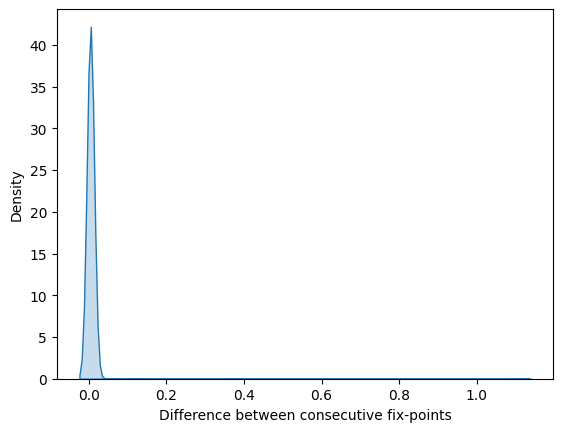

In [22]:
sns.kdeplot(z_diff_norm, fill=True)
plt.xlabel('Difference between consecutive fix-points')
# plt.yscale('log')
# plt.savefig(f'{figure_path}/distances_consecutive_fixpoints.pdf')

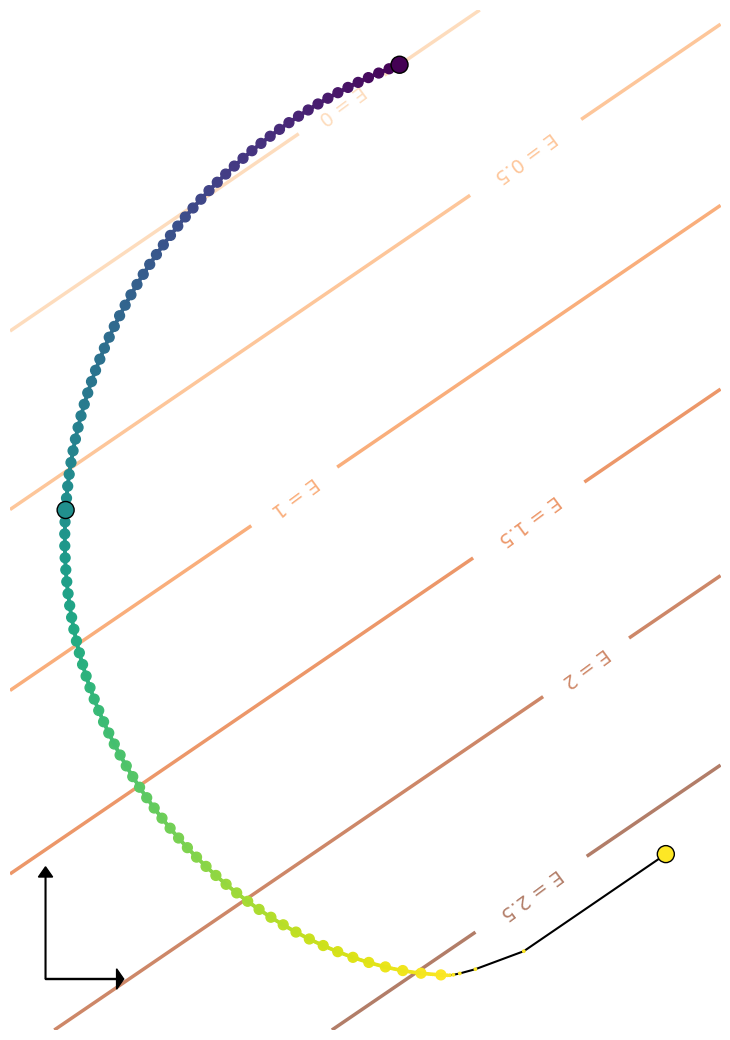

In [43]:
which = 'z'
# which = 'g'

save = True
# save = False
light = True

pc1 = 0
pc2 = 1

around = 20
around = 1_000_000
around = 150
# around = 10
every = 1

heatmap = True
imshow = True          # whether to draw the imshow background
contour = True
colored_contours = False  # colour contours with the heatmap cmap instead of black

if light:
    contour = 2.5 # linewidth
    imshow = False
    colored_contours = True

if 'cumulene' in molecule_name:
    pc1 = 1
    pc2 = 0
    
    around = None
    every = 4
    
if 'cumulene' in molecule_name: # heatmap, contour
    z_shape = z.shape[1:]
    U12 = Uz_k[:, [pc1, pc2]]
    U1, U2 = U12.T.view((2, *z_shape))
    n = 91
    margin = 0.2
    min1 = float((align[pc1] - align[pc1, 0]).min()) - margin
    max1 = float((align[pc1] - align[pc1, 0]).max()) + margin
    min2 = float((align[pc2] - align[pc2, 0]).min()) - margin
    max2 = float((align[pc2] - align[pc2, 0]).max()) + margin
    scaled_U1 = torch.linspace(min1, max1, n, device=U1.device).view(-1, 1, 1, 1, 1) * U1[None, None]
    scaled_U2 = torch.linspace(min2, max2, n, device=U1.device).view(1, -1, 1, 1, 1) * U2[None, None]
    grid = z[0].view(z_shape)[None, None] + scaled_U1 + scaled_U2
    f_E = nnpot.output_modules[0].outnet
    E_grid = f_E(grid[:, :, :, 0]).sum((2,3)).detach().cpu().T

    # PC coordinates (needed for E_ref and contour)
    x, y = project_pc_coords(grid.view((-1, *z_shape)), mean, U12).T

    # Reference: grid energy at projected position of first line conformation
    xi = (x.view(n, n)[:, 0] - align[pc1, 0]).abs().argmin()
    yi = (y.view(n, n)[0, :] - align[pc2, 0]).abs().argmin()
    E_grid = E_grid - E_grid[yi, xi]

    if heatmap:
        if imshow:
            plt.imshow(E_grid, extent=[x.min(), x.max(), y.min(), y.max()], 
                origin='lower', cmap='Oranges', aspect='auto', zorder=-1000)
            # plt.colorbar(label='Value')
        
    if contour:
        # Add contour lines
        contour_kw = dict(cmap='Oranges', vmin=-1.) if colored_contours else dict(colors='black')
        levels = 10
        levels = 0., .5, 1., 1.5, 2., 2.5
        contours = plt.contour(x.view((n, n)), y.view((n, n)), E_grid.T, levels=levels, linewidths=contour, alpha=0.6, zorder=-999, **contour_kw)
        labels = plt.clabel(contours, inline=True, fontsize=14, fmt='E = %g')  # Add labels to contour lines
        
        # Flip all labels 180 degrees while preserving their contour-aligned rotation
        for label in labels:
            label.set_rotation(label.get_rotation() + 236)
    

if True: # pick, lineplot
    i_interest = int((i_max_align_diff if which=='z' else i_max_align_diff_g)[0])   # diff index
    # i_interest = (i_max_diff_norm if which=='z' else i_max_diff_norm_g)

    sel = dat = align if which=='z' else align_g
    if around is not None:
        show = slice(i_interest - around, i_interest + around + 2)
        sel = dat[:, show]

    plt.plot(sel[pc1], sel[pc2], 'k-', zorder=1)
if 'cumulene' not in molecule_name:
    heatmap = False
    contour = False
    
    # all
    plt.scatter(sel[pc1, ::every], sel[pc2, ::every], c=range(0, sel.shape[1], every), zorder=2)   
    
    # red
    plt.scatter(
        dat[pc1, [i_interest, i_interest + 1]],
        dat[pc2, [i_interest, i_interest + 1]],
        c='r',
        zorder=3
    )
    # plt.plot(
    #     dat[pc1, [i_interest,i_interest + 1]],
    #     dat[pc2, [i_interest,i_interest + 1]],
    #     # 'k-',
    #     c='r',
    #     zorder=4
    # )
    plt.xlabel(f'Alignment with PC{pc1+1}')
    plt.ylabel(f'Alignment with PC{pc2+1}')
else:
    # all
    every = 10
    plt.scatter(sel[pc1, ::every], sel[pc2, ::every], c=range(0, sel.shape[1], every), zorder=2, s=50)   
    every = 1
    plt.scatter(sel[pc1, ::every], sel[pc2, ::every], c=range(0, sel.shape[1], every), zorder=2, s=3)   
    
    
    plt.gca().set_aspect('equal')
    
    plt.scatter(
        dat[pc1, [0, 500, 999]],
        dat[pc2, [0, 500, 999]],
        c=[0,499,999],
        edgecolors='black',
        s=150,
        zorder=10
    )
    
    plt.gcf().set_size_inches(8.5, 10.5)
    # plt.gca().invert_xaxis()
    plt.gca().invert_yaxis()
    plt.axis('off')
    
    ax = plt.gca()
    # Add arrows to bottom left
    ax.arrow(0.05, 0.05, 0.1, 0, head_width=0.02, head_length=0.01, 
            fc='black', ec='black', transform=ax.transAxes)
    ax.arrow(0.05, 0.05, 0, 0.1, head_width=0.02, head_length=0.01, 
            fc='black', ec='black', transform=ax.transAxes)

    if False:
        # Add labels
        ax.text(0.17, 0.05, f'PC{pc1+1}', transform=ax.transAxes, fontsize=10, va='center')
        ax.text(0.05, 0.17, f'PC{pc2+1}', transform=ax.transAxes, fontsize=10, ha='center')

if 'cumulene' in molecule_name and True: # colorbars
    
    from mpl_toolkits.axes_grid1.inset_locator import inset_axes

    width="6%"
    height="40%"

    ax = plt.gca()
    
    if not light:
        # Viridis colorbar (0 to sel.shape[1])
        ax_cb1 = inset_axes(ax, width=width, height=height, loc='center right', borderpad=8, 
                        bbox_to_anchor=(0, -0.1, 1, 1), bbox_transform=ax.transAxes)
        norm1 = plt.Normalize(vmin=0, vmax=sel.shape[1])
        sm1 = plt.cm.ScalarMappable(cmap='viridis', norm=norm1)
        sm1.set_array([])
        cbar1 = plt.colorbar(sm1, cax=ax_cb1)
        cbar1.set_ticks([0, sel.shape[1]/2, sel.shape[1]])
        cbar1.set_ticklabels(['0°', '45°', '90°'])
        cbar1.ax.set_title('Torsion', fontsize=10, pad=10, color='black')
        cbar1.ax.yaxis.set_ticks_position('left')
        cbar1.ax.yaxis.set_label_position('left')

    if heatmap and imshow:
        # Oranges colorbar (Energy)
        ax_cb2 = inset_axes(ax, width=width, height=height, loc='center right', borderpad=3, 
                        bbox_to_anchor=(0, -0.1, 1, 1), bbox_transform=ax.transAxes)
        E_min, E_max = E_grid.min(), E_grid.max()
        norm2 = plt.Normalize(vmin=E_min, vmax=E_max)
        sm2 = plt.cm.ScalarMappable(cmap='Oranges', norm=norm2)
        sm2.set_array([])
        cbar2 = plt.colorbar(sm2, cax=ax_cb2)
        cbar2.set_ticks(np.arange(np.ceil(cbar2.vmin), np.floor(cbar2.vmax)+1, 1))
        cbar2.ax.set_title('Potential\nEnergy', fontsize=10, pad=10, color='black')
        cbar2.ax.tick_params(colors='black')  # Makes tick labels white

    
plt.tight_layout()
if save:
    postfix = '' if (dat.shape == sel.shape) else f'_zoom_{around:04d}'
    if heatmap:
        postfix+='_heatmap'
    if contour:
        postfix+='_contour'
    if light:
        postfix+='_light'
    plt.savefig(f'{figure_path}/{which}_pc{pc1}{pc2}{postfix}.pdf')

In [262]:
f'{figure_path}/{which}_pc{pc1}{pc2}{postfix}.pdf'

'~/imlff/../imlff-paper/figures/fixpoint_trajectory/cumulene1_train_qcml-group_dev-v10_model-l87qqzve:v160//z_pc10_heatmap_contour.pdf'

Text(0.5, 0, 'Torsion')

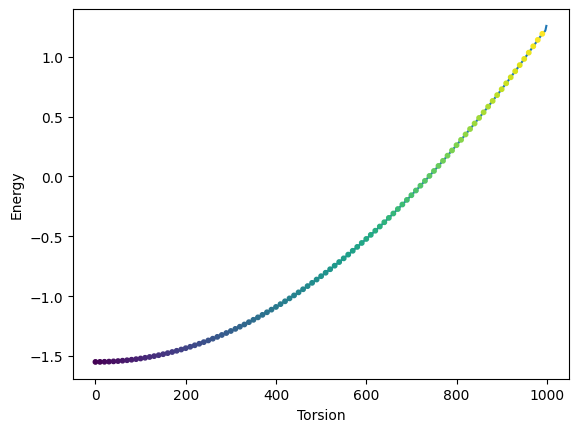

In [204]:
E_z = f_E(z[:, :, 0]).sum((1,2)).detach().cpu()
x = np.arange(len(E_z))
plt.plot(x, E_z)
every=10
plt.scatter(x[::every], E_z[::every], c=range(0, sel.shape[1], every), zorder=2, s=10)   
plt.ylabel('Energy')
plt.xlabel('Torsion')

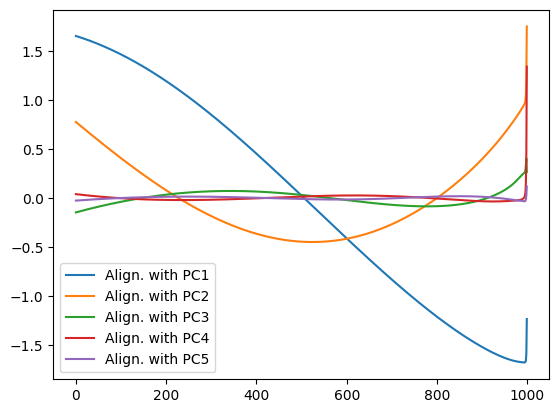

In [224]:
which = 'z'
# which = 'g'

around = 100
around = 10
around = None
i_interest = (i_max_align_diff if which=='z' else i_max_align_diff_g)[0]
# i_interest = (i_max_diff_norm if which=='z' else i_max_diff_norm_g)

sel = dat = align if which=='z' else align_g
if around is not None:
    show = slice(i_interest-around, i_interest+around+1)
    sel = dat[:, show]

# calculate how much every instance in z_flat is explained by the first 2 principal components
inds = [0]
inds = range(5)

plt.plot(sel[inds].T)
plt.legend([f"Align. with PC{i+1}" for i in inds])

if 'cumulene' not in molecule_name: # red
    # vertical red line at 'along' dashed
    plt.axvline((around or i_interest), color='r', linestyle='--')
    plt.axvline((around or i_interest)+1, color='r', linestyle='--')

zoom_postfix = '' if (dat.shape == sel.shape) else f'_zoom_{around:04d}' 
plt.savefig(f'{figure_path}/{which}_lineplot_pc{''.join([str(i) for i in inds])}{zoom_postfix}.pdf')